# Extension Silver : météo indépendante
ERA5 via Open-Meteo, boîte londonienne en 2023. Voir `reports/weather_methodology.md`. Les autres accidents restent hors périmètre.


In [1]:
from pathlib import Path
import json
import pandas as pd
root = Path.cwd() if (Path.cwd() / 'reports').exists() else Path.cwd().parent
metrics = json.loads((root / 'reports/weather_quality.json').read_text())
pd.Series({k: v for k, v in metrics.items() if k not in ('source_manifest', 'confusion_matrix')})


run_id                                               20261116T133604389268Z
rows                                                                 513801
in_scope                                                              25695
comparable                                                            22577
agreements                                                            18407
max_distance_km                                                    16.25107
max_time_delta_minutes                                                 30.0
status_counts             {'ambiguous_local_time': 6, 'outside_scope': 4...
rule_version                                                era5-weather-v1
matched                                                               25689
coverage_in_scope_pct                                                99.977
agreement_pct                                                         81.53
dtype: object

In [2]:
confusion = pd.DataFrame(metrics['confusion_matrix'])
confusion.pivot(index='weather_conditions', columns='weather_conditions_reconstructed', values='count').fillna(0).astype(int)


weather_conditions_reconstructed,1,2,3,4,5
weather_conditions,,,,,
1,16442,2803,13,10,6
2,872,1949,44,1,3
3,4,15,16,0,0
4,146,29,1,0,2
5,46,123,5,3,0
6,2,1,0,0,0
7,40,1,0,0,0


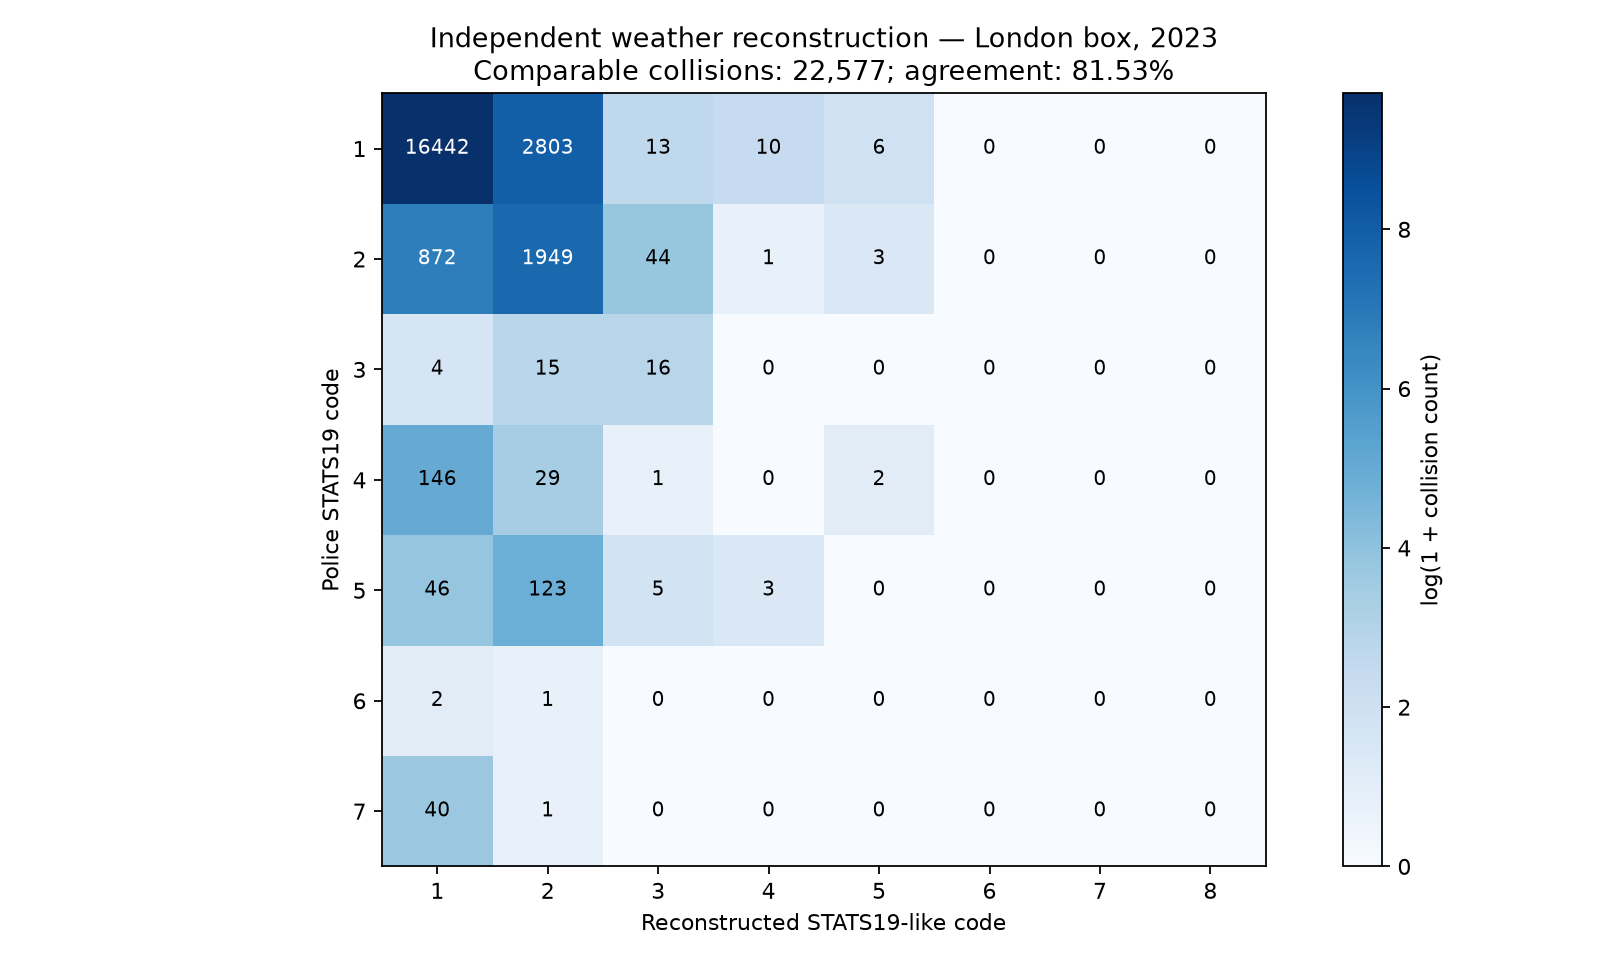

In [3]:
from IPython.display import Image, display
display(Image(filename=str(root / 'reports/weather_confusion.png')))


Le taux d'accord exclut les codes policiers inconnus/autres. La réanalyse ne représente pas une vérité terrain à chaque accident. Le seuil de vent est une hypothèse de projet ; les désaccords et les exclusions sont des résultats de qualité à documenter.
